# Знакомимся с классификацией

Проект: классификация одежды Fashion-MNIST

Задача: по изображению 28×28 определить один из 10 классов одежды:

T-shirt, Trouser, Pullover, Dress, Coat, Sandal, Shirt, Sneaker, Bag, Ankle boot.

Датасет: 60 000 train + 10 000 test, изображения маленькие, датасет автоматически скачивается через torchvision.

## Анализ данных

#### Загрузка

In [1]:
from torch.utils.data import DataLoader
from torchvision import datasets, transforms

transform = transforms.ToTensor()

train_dataset = datasets.FashionMNIST(
    root="./data",
    train=True,
    download=True,
    transform=transform,
)

test_dataset = datasets.FashionMNIST(
    root="./data",
    train=False,
    download=True,
    transform=transform,
)

train_loader = DataLoader(
    train_dataset,
    batch_size=128,
    shuffle=True,
)

test_loader = DataLoader(
    test_dataset,
    batch_size=128,
)

class_names = [
    "T-shirt/top",
    "Trouser",
    "Pullover",
    "Dress",
    "Coat",
    "Sandal",
    "Shirt",
    "Sneaker",
    "Bag",
    "Ankle boot",
]


In [2]:
print("Train samples:", len(train_dataset))
print("Test samples:", len(test_dataset))
print("Number of classes:", len(class_names))

Train samples: 60000
Test samples: 10000
Number of classes: 10


#### Примеры

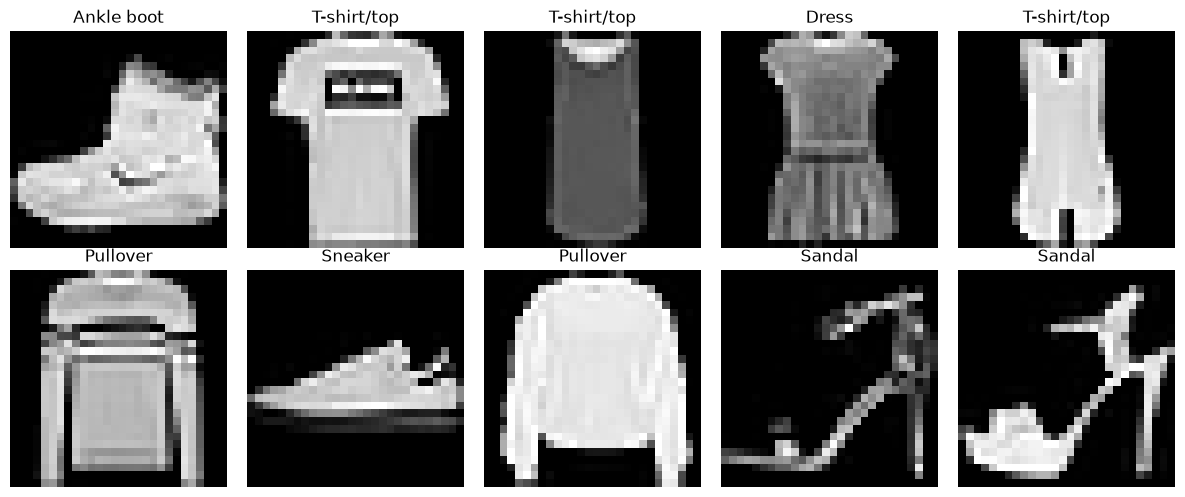

In [3]:
import matplotlib.pyplot as plt

fig, axes = plt.subplots(2, 5, figsize=(12, 5))

for i, ax in enumerate(axes.flat):
    image, label = train_dataset[i]

    ax.imshow(image.squeeze(), cmap="gray")
    ax.set_title(class_names[label])
    ax.axis("off")

plt.tight_layout()
plt.show()

#### Формат

In [4]:
image, label = train_dataset[0]

print("Image shape:", image.shape)
print("Label:", label)
print("Class:", class_names[label])
print("Min pixel value:", image.min().item())
print("Max pixel value:", image.max().item())

Image shape: torch.Size([1, 28, 28])
Label: 9
Class: Ankle boot
Min pixel value: 0.0
Max pixel value: 1.0


#### Распределение классов

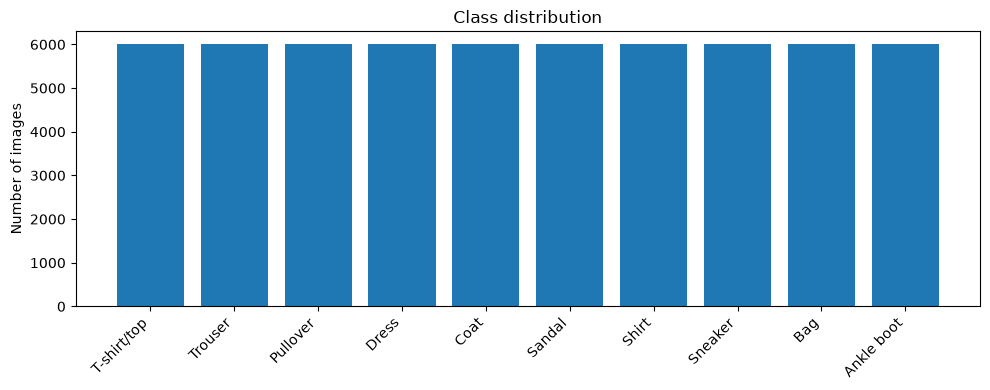

In [5]:
import numpy as np

targets = train_dataset.targets.numpy()

unique, counts = np.unique(targets, return_counts=True)

plt.figure(figsize=(10, 4))
plt.bar(
    [class_names[i] for i in unique],
    counts,
)

plt.xticks(rotation=45, ha="right")
plt.ylabel("Number of images")
plt.title("Class distribution")
plt.tight_layout()
plt.show()

## Инференс

In [6]:
import torch.nn as nn

class SimpleCNN(nn.Module):
    def __init__(self):
        super().__init__()

        self.features = nn.Sequential(
            nn.Conv2d(1, 16, kernel_size=3, padding=1),
            nn.ReLU(),
            nn.MaxPool2d(2),

            nn.Conv2d(16, 32, kernel_size=3, padding=1),
            nn.ReLU(),
            nn.MaxPool2d(2),
        )

        self.classifier = nn.Sequential(
            nn.Flatten(),
            nn.Linear(32 * 7 * 7, 64),
            nn.ReLU(),
            nn.Linear(64, 10),
        )

    def forward(self, x):
        x = self.features(x)
        return self.classifier(x)


In [7]:
import torch
import torch.nn as nn

device = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)
print(device)

model = SimpleCNN().to(device)

criterion = nn.CrossEntropyLoss()
optimizer = torch.optim.Adam(model.parameters(), lr=1e-3)


cpu


### Оценка

In [8]:
def evaluate_model(model, data_loader, device):
    model.eval()

    all_labels = []
    all_predictions = []

    with torch.no_grad():
        for images, labels in data_loader:
            images = images.to(device)

            logits = model(images)
            predictions = logits.argmax(dim=1)

            all_labels.extend(labels.numpy())
            all_predictions.extend(predictions.cpu().numpy())

    all_labels = np.array(all_labels)
    all_predictions = np.array(all_predictions)

    accuracy = (all_labels == all_predictions).mean()

    print(f"Accuracy: {accuracy:.3f}")

    return all_labels, all_predictions, accuracy

In [15]:
all_labels, all_predictions, accuracy = evaluate_model(
    model,
    test_loader,
    device,
)

Accuracy: 0.893


### Обучение


In [12]:
# ~ 2 min

for epoch in range(5):
    model.train()

    total_loss = 0

    for images, labels in train_loader:
        images = images.to(device)
        labels = labels.to(device)

        optimizer.zero_grad()

        logits = model(images)

        loss = criterion(logits, labels)
        loss.backward()

        optimizer.step()

        total_loss += loss.item()

    print(
        f"Epoch {epoch + 1}: "
        f"loss = {total_loss / len(train_loader):.4f}"
    )


Epoch 1: loss = 0.5922
Epoch 2: loss = 0.3697
Epoch 3: loss = 0.3264
Epoch 4: loss = 0.2958
Epoch 5: loss = 0.2748


#### Confusion matrix

In [10]:
def plot_confusion_matrix(
    all_labels,
    all_predictions,
    class_names,
):
    num_classes = len(class_names)

    confusion_matrix = torch.zeros(
        num_classes,
        num_classes,
        dtype=torch.int64,
    )

    for true_label, pred_label in zip(
        all_labels,
        all_predictions,
    ):
        confusion_matrix[true_label, pred_label] += 1

    cm = confusion_matrix.float()

    cm_normalized = (
        cm / cm.sum(dim=1, keepdim=True)
    )

    plt.figure(figsize=(10, 8))

    plt.imshow(
        cm_normalized.numpy(),
        cmap="Blues",
        vmin=0,
        vmax=1,
    )

    plt.xticks(
        range(num_classes),
        class_names,
        rotation=45,
        ha="right",
    )

    plt.yticks(
        range(num_classes),
        class_names,
    )

    plt.xlabel("Predicted class")
    plt.ylabel("True class")
    plt.title("Normalized Confusion Matrix")

    plt.colorbar()

    for i in range(num_classes):
        for j in range(num_classes):
            plt.text(
                j,
                i,
                f"{cm_normalized[i, j]:.2f}",
                ha="center",
                va="center",
                fontsize=8,
            )

    plt.tight_layout()
    plt.show()

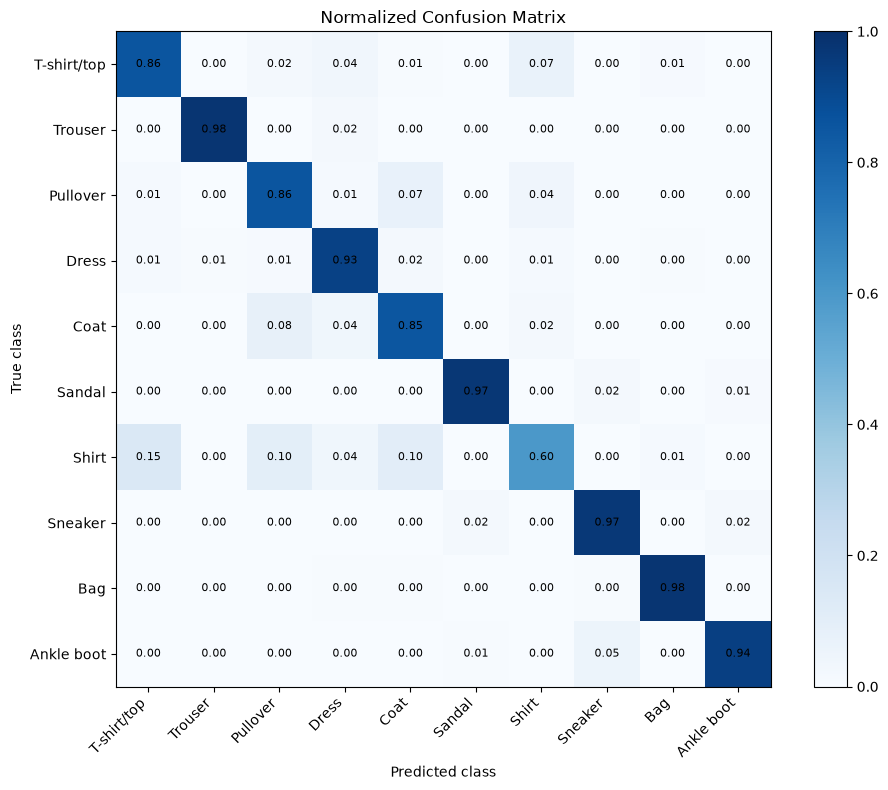

In [16]:
plot_confusion_matrix(
    all_labels,
    all_predictions,
    class_names,
)

#### Реальные ошибки

In [ ]:
def plot_errors(
    dataset,
    all_labels,
    all_predictions,
    class_names,
    num_images=15,
):
    errors = np.where(all_labels != all_predictions)[0]

    num_images = min(num_images, len(errors))
    rows = 3
    cols = 5

    fig, axes = plt.subplots(
        rows,
        cols,
        figsize=(12, 8),
    )

    for ax in axes.flat:
        ax.axis("off")

    for ax, index in zip(
        axes.flat,
        errors[:num_images],
    ):
        image, true_label = dataset[index]
        pred_label = all_predictions[index]

        ax.imshow(
            image.squeeze(),
            cmap="gray",
        )

        ax.set_title(
            f"True: {class_names[true_label]}\n"
            f"Pred: {class_names[pred_label]}",
            fontsize=9,
        )

        ax.axis("off")

    plt.tight_layout()
    plt.show()

In [ ]:
plot_errors(
    test_dataset,
    all_labels,
    all_predictions,
    class_names,
)

#### Готовые архитектуры :: ResNet

In [17]:
import torch
import torch.nn as nn
from torchvision.models import resnet18
from torch.utils.data import DataLoader, Subset

# for CPU train
train_size = 5_000

train_subset = Subset(
    train_dataset,
    range(train_size),
)

train_loader = DataLoader(
    train_subset,
    batch_size=256,
    shuffle=True,
)

test_loader = DataLoader(
    test_dataset,
    batch_size=256,
    shuffle=False,
)


In [18]:
print("Train samples:", len(train_subset))
print("Test samples:", len(test_dataset))
print("Number of classes:", len(class_names))

Train samples: 5000
Test samples: 10000
Number of classes: 10


In [19]:
model = resnet18(weights=None)

# 1 канал вместо RGB
model.conv1 = nn.Conv2d(
    in_channels=1,
    out_channels=64,
    kernel_size=3,
    stride=1,
    padding=1,
    bias=False,
)

# Для маленьких 28x28 изображений
model.maxpool = nn.Identity()

# Fashion-MNIST: 10 классов
model.fc = nn.Linear(
    model.fc.in_features,
    10,
)

model = model.to(device)
num_parameters = sum(
    p.numel()
    for p in model.parameters()
)

print(f"Parameters: {num_parameters:,}")

Parameters: 11,172,810


In [ ]:
# train
# ~10 min

criterion = nn.CrossEntropyLoss()

optimizer = torch.optim.Adam(
    model.parameters(),
    lr=1e-3,
)


num_epochs = 2

for epoch in range(num_epochs):
    model.train()

    total_loss = 0
    correct = 0
    total = 0

    for batch_idx, (images, labels) in enumerate(train_loader):
        images = images.to(device)
        labels = labels.to(device)

        optimizer.zero_grad()

        logits = model(images)

        loss = criterion(logits, labels)

        loss.backward()
        optimizer.step()

        total_loss += loss.item()

        predictions = logits.argmax(dim=1)

        correct += (predictions == labels).sum().item()
        total += labels.size(0)

        if batch_idx % 10 == 0:
            print(
                f"Epoch {epoch + 1}/{num_epochs} "
                f"| batch {batch_idx}/{len(train_loader)} "
                f"| loss {loss.item():.4f}"
            )

    train_accuracy = correct / total

    print(
        f"\nEpoch {epoch + 1}: "
        f"loss = {total_loss / len(train_loader):.4f}, "
        f"accuracy = {train_accuracy:.3f}\n"
    )


#### Evaluation

In [ ]:
all_labels, all_predictions, accuracy = evaluate_model(
    model,
    test_loader,
    device,
)

#### Confusion matrix

In [ ]:
plot_confusion_matrix(
    all_labels,
    all_predictions,
    class_names,
)

#### Model errors

In [ ]:
plot_errors(
    test_dataset,
    all_labels,
    all_predictions,
    class_names,
)

#### Доработки

* Попробовать менять batch_size, learning_rate, количество эпох.
* Добавить простую augmentation.